In [6]:
# Reference: https://herbie.readthedocs.io/en/stable/gallery/bonus_notebooks/time-height.html
from functions import *
from herbie import FastHerbie, HerbieLatest
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import numpy as np


In [59]:
# https://herbie.readthedocs.io/en/stable/gallery/noaa_models/hrrr.html
H = HerbieLatest(
    model="hrrr",
    product="sfc",
    fxx=1,
)
t2m_ds = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
               )

t2m_ds

💔 Did not find ┊ model=hrrr ┊ product=sfc ┊ 2024-Dec-03 18:00 UTC F01
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Dec-03 17:00 UTC F01 ┊ GRIB2 @ aws ┊ IDX @ aws


<xarray.Dataset> Size: 38MB
Dimensions:              (y: 1059, x: 1799)
Coordinates:
    time                 int64 8B 1733245200
    step                 float64 8B 1.0
    heightAboveGround    float64 8B 2.0
    latitude             (y, x) float64 15MB 21.14 21.15 21.15 ... 47.85 47.84
    longitude            (y, x) float64 15MB 237.3 237.3 237.3 ... 299.0 299.1
    valid_time           float64 8B 1.733e+09
    gribfile_projection  object 8B None
Dimensions without coordinates: y, x
Data variables:
    t2m                  (y, x) float32 8MB 294.9 294.9 294.9 ... 273.3 273.3
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    model:                   hrrr
    product:                 sfc
    description:             High-Resolution Rapid Refresh - CONUS
    remote_grib:             https://noaa-hrrr-bdp-pds.s3.amazonaws.com/hrrr....
    local_grib:              /Users/jglarson/data/hrrr/20241203/subset_59e4fd...
    search:                  TMP:2 m above

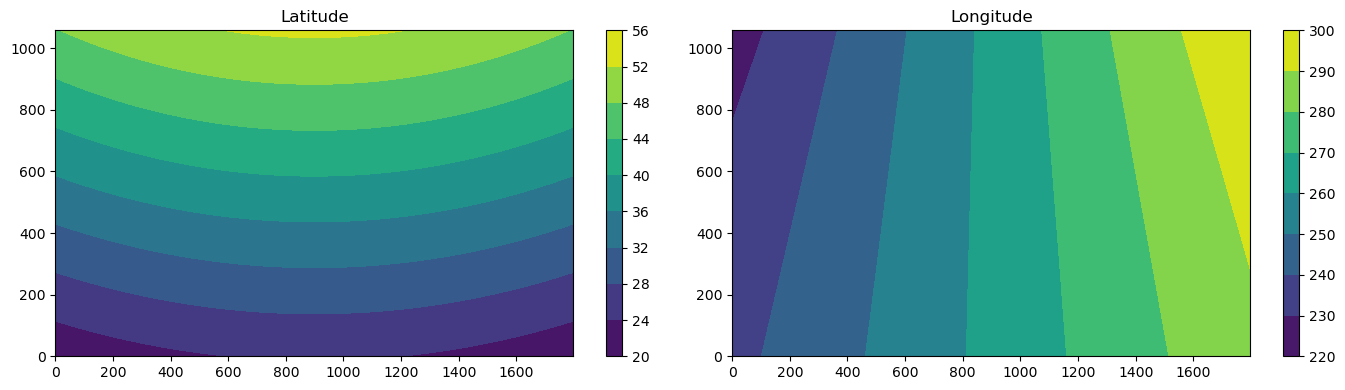

In [ ]:
# Create figure and subplots
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 4))

# First subplot - Latitude
im1 = ax1.contourf(t2m_ds.latitude)
ax1.set_title('Latitude')
plt.colorbar(im1, ax=ax1)

# Second subplot - Longitude 
im2 = ax2.contourf(t2m_ds.longitude)
ax2.set_title('Longitude')
plt.colorbar(im2, ax=ax2)

# Adjust layout to prevent overlap
plt.tight_layout()

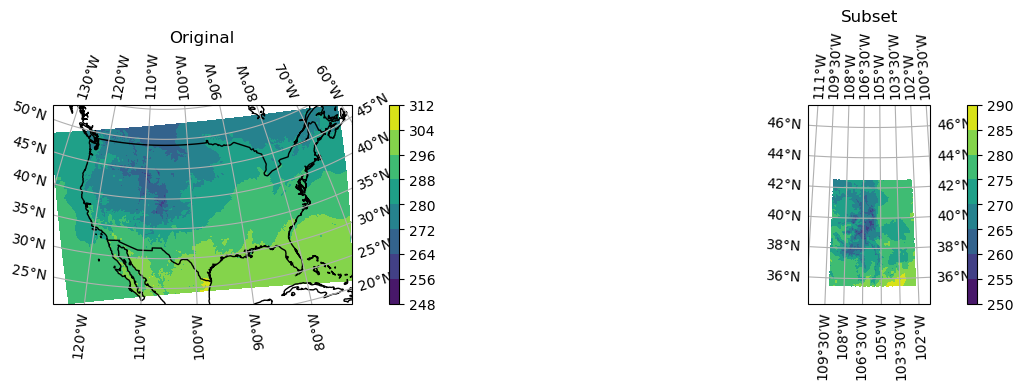

In [27]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Create AzimuthalEquidistant projection
proj = ccrs.AzimuthalEquidistant(central_longitude=-105.7, central_latitude=39)

# Create figure and subplots with projection
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 4),
                              subplot_kw={'projection': proj})

# First subplot - Original data
im1 = ax1.contourf(t2m_ds.longitude.values, t2m_ds.latitude.values, t2m_ds['t2m'].values,
                   transform=ccrs.PlateCarree())
ax1.set_title('Original')
ax1.coastlines()
ax1.add_feature(cfeature.BORDERS)
ax1.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
plt.colorbar(im1, ax=ax1)

# Second subplot - Subset data
subset = sel_region(t2m_ds['t2m'], [39, 360-105.7], 7)
im2 = ax2.contourf(subset.longitude.values, subset.latitude.values, subset.values,
                   transform=ccrs.PlateCarree())
ax2.set_title('Subset')
ax2.coastlines()
ax2.add_feature(cfeature.BORDERS)
ax2.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
plt.colorbar(im2, ax=ax2)

plt.tight_layout()

# Generate a time series

In [33]:
# https://herbie.readthedocs.io/en/stable/gallery/noaa_models/hrrr.html
# dates = pd.date_range("2024-11-21 18:00", periods=1, freq="1h")
today = pd.Timestamp.now().date()
dates = pd.DatetimeIndex([pd.Timestamp(f"{today} 18:00")])
H = FastHerbie(
    dates,
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 31)),
)

points = pd.DataFrame({"longitude": [-105.082396, -80.172745], # [Fort Collins, Erie]
                       "latitude": [40.548843, 42.083850],
                       })

t2m_ds = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  ).herbie.pick_points(points, method="nearest")

t2m_ds

t2m_ds = (t2m_ds['t2m'] - 273.15) * 1.8 + 32

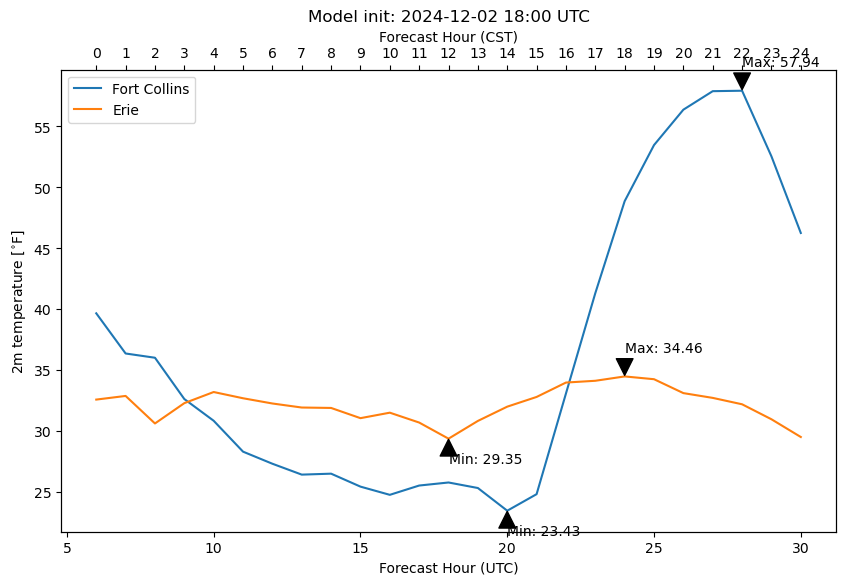

In [34]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {dates[0].strftime('%Y-%m-%d %H:%M')} UTC")

fort_collins = t2m_ds.sel(point=0).values
city2 = t2m_ds.sel(point=1).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,31), fort_collins, label='Fort Collins')
ax1.plot(np.arange(6,31), city2, label='Erie')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel(r'2m temperature [$^{\circ}$F]')

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,31))
ax2.set_xticklabels([str(h-6) for h in range(6,31)])
ax2.set_xlabel('Forecast Hour (CST)')

# Annotate max and min for Fort Collins
max_fc = np.max(fort_collins)
min_fc = np.min(fort_collins)
max_fc_idx = np.argmax(fort_collins)
min_fc_idx = np.argmin(fort_collins)

plt.annotate(f'Max: {max_fc:.2f}', xy=(max_fc_idx + 6, max_fc), xytext=(max_fc_idx + 6, max_fc + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_fc:.2f}', xy=(min_fc_idx + 6, min_fc), xytext=(min_fc_idx + 6, min_fc - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))

# Annotate max and min for Wichita Falls
max_wf = np.max(city2)
min_wf = np.min(city2)
max_wf_idx = np.argmax(city2)
min_wf_idx = np.argmin(city2)

plt.annotate(f'Max: {max_wf:.2f}', xy=(max_wf_idx + 6, max_wf), xytext=(max_wf_idx + 6, max_wf + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_wf:.2f}', xy=(min_wf_idx + 6, min_wf), xytext=(min_wf_idx + 6, min_wf - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))


# Add legend
ax1.legend()

plt.show()

## Precip

In [ ]:
today = pd.Timestamp.now().date()
dates = pd.DatetimeIndex([pd.Timestamp(f"{today} 18:00")])
H = FastHerbie(
    dates,
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 31)),
)
H

In [ ]:
# H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
#                   )
today = pd.Timestamp.now().date()
dates = pd.DatetimeIndex([pd.Timestamp(f"{today} 18:00")])
H = FastHerbie(
    dates,
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 31)),
)
H
H.inventory("APCP:.*0-30.*")
H.inventory("TMP:2 m above")
# H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
#                   )
                
tp = H.xarray("APCP", backend_kwargs={'decode_times':False}).herbie.pick_points(points, method="nearest")


<xarray.Dataset> Size: 704B
Dimensions:              (step: 25, point: 2)
Coordinates:
    time                 int64 8B 1733162400
  * step                 (step) float64 200B 6.0 7.0 8.0 9.0 ... 28.0 29.0 30.0
    surface              float64 8B 0.0
    latitude             (point) float64 16B 40.55 42.09
    longitude            (point) float64 16B 254.9 279.8
    valid_time           (step) float64 200B 1.733e+09 1.733e+09 ... 1.733e+09
    gribfile_projection  object 8B None
    point_grid_distance  (point) float64 16B 0.9413 0.4454
    point_longitude      (point) float64 16B -105.1 -80.17
    point_latitude       (point) float64 16B 40.55 42.08
Dimensions without coordinates: point
Data variables:
    tp                   (step, point) float32 200B 0.0 0.01 0.0 ... 0.0 0.43
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    model:                   hrrr
    product:                 sfc
    description:             High-Resolution Rapid Refresh - CONUS
    search:                  APCP

## TO DO: Fix below error about not finding the GRIB files

In [64]:
H = FastHerbie(
    pd.DatetimeIndex([get_recent_6_hour_multiple_plus_30()]),
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 31)),
)
H
H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  )


Could not find 12/13 GRIB files.


<xarray.Dataset> Size: 130MB
Dimensions:              (step: 13, y: 1059, x: 1799)
Coordinates:
    time                 int64 8B 1733230800
  * step                 (step) float64 104B 6.0 7.0 8.0 9.0 ... 16.0 17.0 18.0
    heightAboveGround    float64 8B 2.0
    latitude             (y, x) float64 15MB 21.14 21.15 21.15 ... 47.85 47.84
    longitude            (y, x) float64 15MB 237.3 237.3 237.3 ... 299.0 299.1
    valid_time           (step) float64 104B 1.733e+09 1.733e+09 ... 1.733e+09
    gribfile_projection  object 8B None
Dimensions without coordinates: y, x
Data variables:
    t2m                  (step, y, x) float32 99MB 294.4 294.4 ... 272.7 272.7
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    model:                   hrrr
    product:                 sfc
    description:             High-Resolution Rapid Refresh - CONUS
    search:                  TMP:2 m above

In [66]:
t2m = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  )['t2m']

In [67]:
t2m

<xarray.DataArray 't2m' (step: 13, y: 1059, x: 1799)> Size: 99MB
array([[[294.43024, 294.43024, 294.43024, ..., 299.80524, 299.86774,
         299.86774],
        [294.43024, 294.43024, 294.43024, ..., 299.80524, 299.80524,
         299.80524],
        [294.43024, 294.43024, 294.43024, ..., 299.74274, 299.74274,
         299.80524],
        ...,
        [283.36774, 283.43024, 283.49274, ..., 272.93024, 272.93024,
         273.05524],
        [283.30524, 283.43024, 283.49274, ..., 272.93024, 272.93024,
         273.05524],
        [283.30524, 283.30524, 283.36774, ..., 272.99274, 272.99274,
         273.05524]],

       [[294.46002, 294.46002, 294.39752, ..., 299.64752, 299.71002,
         299.71002],
        [294.39752, 294.39752, 294.39752, ..., 299.64752, 299.64752,
         299.64752],
        [294.39752, 294.39752, 294.39752, ..., 299.58502, 299.58502,
         299.64752],
...
        [283.3609 , 283.4234 , 283.4234 , ..., 272.4859 , 272.4859 ,
         272.6109 ],
        [283.3609 , 283.4234 , 283.4234 , ..., 272.4859 , 272.4859 ,
         272.6109 ],
        [283.2984 , 283.3609 , 283.3609 , ..., 272.5484 , 272.5484 ,
         272.6109 ]],

       [[293.8471 , 293.8471 , 293.8471 , ..., 299.2221 , 299.1596 ,
         299.1596 ],
        [293.8471 , 293.7846 , 293.7846 , ..., 299.1596 , 299.1596 ,
         299.1596 ],
        [293.7846 , 293.7846 , 293.7221 , ..., 299.1596 , 299.1596 ,
         299.1596 ],
        ...,
        [283.3471 , 283.4096 , 283.4721 , ..., 272.5346 , 272.5971 ,
         272.6596 ],
        [283.3471 , 283.4096 , 283.4096 , ..., 272.5346 , 272.5971 ,
         272.6596 ],
        [283.3471 , 283.3471 , 283.3471 , ..., 272.5971 , 272.6596 ,
         272.6596 ]]], dtype=float32)
Coordinates:
    time                 int64 8B 1733230800
  * step                 (step) float64 104B 6.0 7.0 8.0 9.0 ... 16.0 17.0 18.0
    heightAboveGround    float64 8B 2.0
    latitude             (y, x) float64 15MB 21.14 21.15 21.15 ... 47.85 47.84
    longitude            (y, x) float64 15MB 237.3 237.3 237.3 ... 299.0 299.1
    valid_time           (step) float64 104B 1.733e+09 1.733e+09 ... 1.733e+09
    gribfile_projection  object 8B None
Dimensions without coordinates: y, x
Attributes: (12/37)
    GRIB_paramId:                             167
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      1905141
    GRIB_typeOfLevel:                         heightAboveGround
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_shortName:                           2t
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            air_temperature
    grid_mapping:                             gribfile_projection

# Add NBM

In [35]:
# dates = pd.date_range("2024-11-21 18:00", periods=1, freq="1h")
today = pd.Timestamp.now().date()
dates = pd.DatetimeIndex([pd.Timestamp(f"{today} 18:00")])

H = FastHerbie(dates, model="nbm", fxx=list(range(6, 31)), product="co")
H.inventory(":TMP:2 m above ground:.*fcst:nan")

points = pd.DataFrame({"longitude": [-105.082396, -80.172745], # [Fort Collins, Erie]
                       "latitude": [40.548843, 42.083850],
                       })

ds = H.xarray(":TMP:2 m above ground:.*fcst:nan", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest")

t2m_ds = (ds['t2m'] - 273.15) * 1.8 + 32

👨🏻‍🏭 Created directory: [/Users/jglarson/data/nbm/20241202]


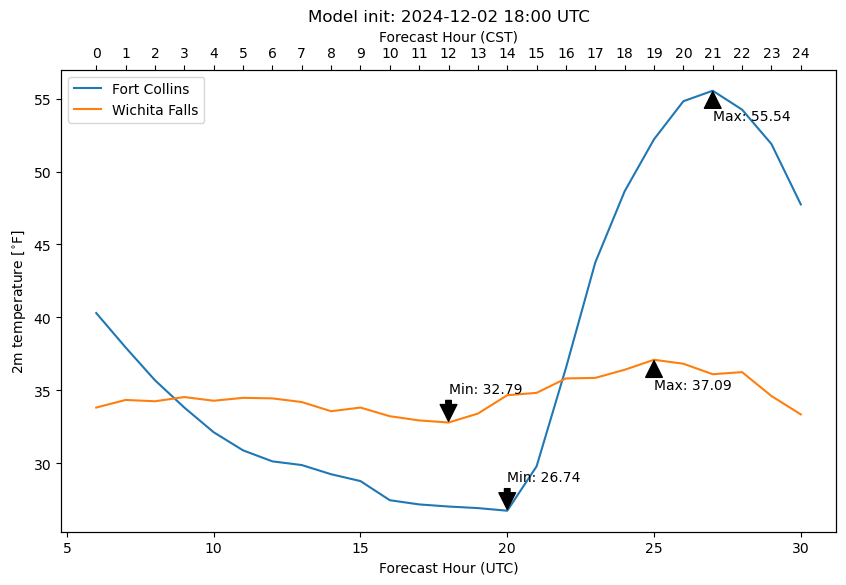

In [36]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {dates[0].strftime('%Y-%m-%d %H:%M')} UTC")

fort_collins = t2m_ds.sel(point=0).values
city2 = t2m_ds.sel(point=1).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,31), fort_collins, label='Fort Collins')
ax1.plot(np.arange(6,31), city2, label='Wichita Falls')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel(r'2m temperature [$^{\circ}$F]')

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,31))
ax2.set_xticklabels([str(h-6) for h in range(6,31)])
ax2.set_xlabel('Forecast Hour (CST)')

# Annotate max and min for Fort Collins
max_fc = np.max(fort_collins)
min_fc = np.min(fort_collins)
max_fc_idx = np.argmax(fort_collins)
min_fc_idx = np.argmin(fort_collins)

plt.annotate(f'Max: {max_fc:.2f}', xy=(max_fc_idx + 6, max_fc), xytext=(max_fc_idx + 6, max_fc - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_fc:.2f}', xy=(min_fc_idx + 6, min_fc), xytext=(min_fc_idx + 6, min_fc + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))

# Annotate max and min for Wichita Falls
max_wf = np.max(city2)
min_wf = np.min(city2)
max_wf_idx = np.argmax(city2)
min_wf_idx = np.argmin(city2)

plt.annotate(f'Max: {max_wf:.2f}', xy=(max_wf_idx + 6, max_wf), xytext=(max_wf_idx + 6, max_wf - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_wf:.2f}', xy=(min_wf_idx + 6, min_wf), xytext=(min_wf_idx + 6, min_wf + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))


# Add legend
ax1.legend()

plt.show()

# To Do: Generate verificatoin statistics to know what model is good and bad